# Estimating Implied Volatilities via Kernel Smoothing

### Mauricio Gómez López

**Erdös Institute — Quantitative Finance, Fall 2026**

---

## Introduction

The goal of this project is to demonstrate that kernel smoothing, a standard technique in statistical learning, can be a powerful tool for estimating implied volatilities and constructing models of volatility curves.

This project is inspired by the ideas and methods from the following paper:

> M. Ulrich, S. Walther, *Option-implied information: What's the vol surface got to do with it?*, Review of Derivatives Research (2020) 23:323–355.

In that paper (listed as [5] in the references section), the authors develop a *1-dimensional kernel smoothing method* for estimating implied volatilities and compare it to other modern methods for constructing models of volatility curves. However, their analysis does not include more traditional models for estimating implied volatilities, such as the Heston model.

With this in mind, this project addresses the following question:


*As a tool for constructing models of volatility curves, how does kernel smoothing perform relative to the Heston model?*


In this project, we shall use a simplified version of Ulrich and Walther's kernel smoothing method, which we shall call the *S-1D kernel smoothing method,* where the *S* stands for 'simplified.' Then, by choosing an appropriate bandwidth parameter (see Section 1 below), we will show that the S-1D kernel smoothing method consistently produces lower root mean squared errors (RMSEs) than the Heston model, indicating that this method produces more accurate estimates of implied volatilities than those produced via the Heston model.  

### Project Overview

The following list contains a brief description of each of the sections of this project.



1.  In Section 1, we give a brief overview of kernel smoothing and introduce the S-1D kernel smoothing method. In this section, we also introduce the data we will work with.
2.   In Section 2, we explain how we determine the optimal bandwidth parameter for the S-1D kernel smoothing method.
3. In Section 3, we review the Heston model and compare it to the S-1D kernel smoothing method.
4. Finally, in Section 4, we present some conclusions of our work and list some limitations of the S-1D kernel smoothing method.

**Acknowledgements.** The author would like to thank Thomas Polstra for allowing him to use the Python code in the Jupyter notebook [4] (see the list of references at the end of this project). Most of the Python code appearing in Code Cells 1, 6, 13, and 15 below comes from that Jupyter notebook.  



In [1]:
#Code Cell 0

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import yfinance as yf

sns.set_style('darkgrid')

import math
from scipy.integrate import quad, trapezoid, cumulative_trapezoid
from scipy.interpolate import interp1d
from scipy.linalg import expm
from scipy.optimize import least_squares

In [32]:
#Code Cell 1

#Black-Scholes Functions

def bs_call(S0,K,sigma,t,r):
    '''
    Black-Scholes Call Price
    Inputs:
    S0: spot price
    K: strike price
    sigma: volatility
    t: time to expiration
    r: risk-free interest rate

    Returns:
    Black-Scholes Price of European Call Option

    '''

    d1 = (np.log(S0/K) + (r + (0.5)*sigma**2)*t)/(sigma*np.sqrt(t))

    d2 = d1 - sigma*np.sqrt(t)

    return S0*norm.cdf(d1) - np.exp(-r*t)*K*norm.cdf(d2)


def bs_vega(S0,K,sigma,t,r):

    '''
    Black-Scholes vega
    Inputs:
    S0: spot price
    K: strike price
    sigma: volatility
    t: time to expiration
    r: risk-free interest rate

    Returns:
    Black-Scholes vega of European Call and Put Options

    '''

    d1 = (np.log(S0/K) + (r + (0.5)*sigma**2)*t)/(sigma*np.sqrt(t))


    return S0*np.sqrt(t)*norm.pdf(d1)


def bs_call_iv_vectorized(
    spots, strikes, ttes, r, prices,
    tol=1e-8,
    max_loops=150,
    vega_floor=1e-5,
    sigma_guess=0.2,
    non_converged_nan = False
):
    spots = np.asarray(spots, dtype=float)
    strikes = np.asarray(strikes, dtype=float)
    ttes = np.asarray(ttes, dtype=float)
    prices = np.asarray(prices, dtype=float)

    # Allow r to be either scalar or array
    r = np.asarray(r, dtype=float)
    r = np.broadcast_to(r, prices.shape)

    N = len(prices)

    Lsigmas = 0.001 * np.ones(N)
    Hsigmas = 5.0 * np.ones(N)
    sigmas = sigma_guess * np.ones(N)

    converged = np.zeros(N, dtype=bool)

    for _ in range(max_loops):
        model_prices = bs_call(spots, strikes, sigmas, ttes, r)

        errors = prices - model_prices

        converged = np.abs(errors) < tol

        if not np.any(~converged):
            break

        active = ~converged

        # If price > model price, volatility is too low
        positive_errors = active & (errors > 0)

        # If price < model price, volatility is too high
        negative_errors = active & (errors < 0)

        Lsigmas[positive_errors] = sigmas[positive_errors]
        Hsigmas[negative_errors] = sigmas[negative_errors]

        vegas = np.maximum(
            bs_vega(
                spots[active],
                strikes[active],
                sigmas[active],
                ttes[active],
                r[active]
            ),
            vega_floor
        )


        sigma_newtons = sigmas[active] + errors[active] / vegas

        good_newtons = (
            (Lsigmas[active] < sigma_newtons)
            & (sigma_newtons < Hsigmas[active])
            & np.isfinite(sigma_newtons)
        )

        sigma_bisect = 0.5 * (Lsigmas[active] + Hsigmas[active])

        sigma_updates = np.where(
            good_newtons,
            sigma_newtons,
            sigma_bisect
        )

        sigmas[active] = sigma_updates

    if non_converged_nan:
        sigmas[~converged] = np.nan

    return sigmas

## 1. The S-1D Kernel Smoothing Method

### 1.1. Overview of Kernel Smoothing

In this section, we give a short introduction to kernel smoothing. For a more in-depth discussion, see [3].

Consider the scatter plot shown in the figure below.

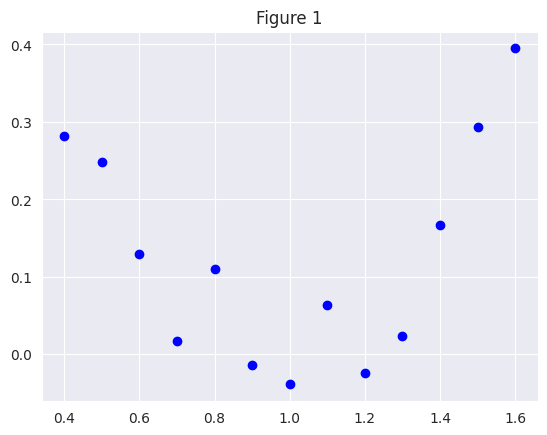

In [33]:
#Code Cell 2

A = np.linspace(0.4,1.6, 13)
Z = np.random.normal(0,0.05, size = 13)
B = (A - 1)**2 + Z

np.random.seed(50)

plt.plot(A,B, 'bo')
plt.title('Figure 1')
plt.show()

The idea of *kernel smoothing* is the following: We wish to fit a smooth curve $y = f(x)$ to this collection of points via the following rule:

For each point $x$ in our space of inputs (in this example, the interval $[0.4,1.6]$), the value $f(x)$ shall be the *weighted average* of all the second coordinates $y_1, \ldots, y_p$ from our collection of observations $(x_1,y_1), \ldots, (x_p,y_p)$. The closer (resp. further) $x_i$ is to $x$, the higher (resp. lower) the weight assigned to $y_i$.

We will achieve this average weighting by using a *kernel function* $k(x, h)$. The variable $h > 0$ in this function is called the *bandwidth parameter*, which controls how much weight each value $y_i$ receives depending on the distance between $x_i$ and $x$. More concretely, the bandwidth parameter $h$ works as follows:

*   As $h$ increases, the total weight will be distributed more uniformly among all the observations $(x_1, y_1), \ldots, (x_p,y_p)$.
*   As $h$ decreases, the total weight will tend to concentrate at those observations $(x_i,y_i)$ with $x_i$ close to $x$.

In this project, we will use the same kernel function $k(x,h)$ of Gaussian shape used in [5]:

$$k(x,h) = \frac{1}{\sqrt{2\pi}} e^{\frac{x^2}{2h}}.$$

Then, the desired function $f(x)$ we wish to use to fit the data in Figure 1 is obtained via the following formula:

$$f(x) = \sum_{i =1}^p \frac{k(x - x_i,h)y_i}{\sum_{1=1}^pk(x - x_i,h) }.$$



In [34]:
#Code Cell 3

def kernel_est(input_values, obs_x_values, obs_y_values, bandwidth):

  '''
  kernel smoothing estimate f(x).
  Inputs:
  input_values = values we will plug into f(x)
  obs_x_values = x-coordinates of observations
  obs_y_values = y-coordinates of observations
  bandwidth = bandwidth paramater h

  '''

  def kernel(x, bandwidth):
    h = bandwidth
    pi = np.pi
    return (1/np.sqrt(2*pi))*np.exp((-x**2)/(2*h))

  bw = bandwidth
  V = np.array(input_values)
  sigmas = obs_y_values

  est_values = np.zeros(len(V))

  for j in range(len(V)):
    est_values[j] = np.sum((kernel(V[j] - obs_x_values, bw)*sigmas)/(np.sum(kernel(V[j] - obs_x_values, bw))))

  return est_values

By the above discussion, it is clear that high values of $h$ will lead to *underfitting*, whereas low values of $h$ will lead to *overfitting*.

We illustrate this point by fitting the data in Figure 1 with curves corresponding to three different values for the bandwidth parameter $h$.

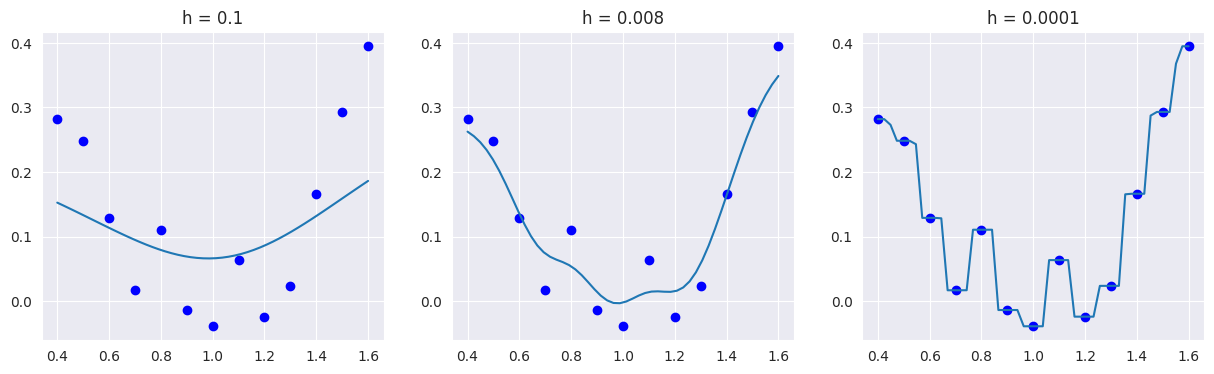

In [35]:
#Code Cell 4

I = np.linspace(0.4,1.6, 50)

h1 = 0.1
h2 = 0.008
h3 = 0.0001

K1 = kernel_est(I, A, B, h1)
K2 = kernel_est(I, A, B, h2)
K3 = kernel_est(I, A, B, h3)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(A,B, 'bo')
axes[0].plot(I,K1)
axes[0].set_title(f'h = {h1}')

axes[1].plot(A,B, 'bo')
axes[1].plot(I,K2)
axes[1].set_title(f'h = {h2}')

axes[2].plot(A,B, 'bo')
axes[2].plot(I,K3)
axes[2].set_title(f'h = {h3}')


plt.show()



### Interlude: Setting up our Data

In the next subsection, we will describe the S-1D kernel smoothing method. Before doing so, we must download and set up the options data we will work with.

In this project, we will use Tesla stock option data from the years 2019 and 2022, and we will set $r = 0.04$ as our risk-free interest rate.  


In [36]:
#Code Cell 5

#TSLA data available at https://www.kaggle.com/datasets/kylegraupe/tsla-daily-eod-options-quotes-2019-2022

option_data = pd.read_csv('tsla_2019_2022.csv',low_memory = False)

In [37]:
#Code Cell 6

# Setting up our data

call_data = option_data[[' [QUOTE_DATE]', ' [UNDERLYING_LAST]',' [EXPIRE_DATE]',\
                      ' [DTE]',' [C_IV]', ' [C_SIZE]', ' [C_BID]', ' [C_ASK]', ' [STRIKE]', ' [STRIKE_DISTANCE_PCT]'] ].copy()

sizes = call_data[' [C_SIZE]'].str.split('x', expand = True).astype(float)

call_data['bid_size'] = sizes[0]
call_data['ask_size'] = sizes[1]

# We restrict our data to values that ensure that our root-solver (the function
# bs_call_iv_vectorized in code cell 1) behaves well.

call_data = call_data[(call_data[' [DTE]'] > 0) & (call_data['bid_size']>10) & (call_data['ask_size']>10)\
    &  (call_data[' [DTE]']<300) &  ((call_data[' [DTE]']>30)) & (call_data[' [STRIKE_DISTANCE_PCT]']<.5)\
    & (call_data[' [UNDERLYING_LAST]']<300)].copy()

call_data[' [C_IV]'] = pd.to_numeric(call_data[' [C_IV]'].str.strip())

call_data[' [C_BID]'] = pd.to_numeric(call_data[' [C_BID]'].str.strip())
call_data[' [C_ASK]'] = pd.to_numeric(call_data[' [C_ASK]'].str.strip())

call_data['mid'] = (0.5)*(call_data[' [C_BID]'] + call_data[' [C_ASK]'])

call_data['tte'] = call_data[' [DTE]']/365

spots = call_data[' [UNDERLYING_LAST]'].values
strikes = call_data[' [STRIKE]'].values
prices = call_data['mid'].values
ttes = call_data['tte'].values

# Set the risk-free interest rate at r = 0.04.

r = .04

# Add a column with the observed BS implied volatilities.

call_data['Imp_Vol'] = bs_call_iv_vectorized(spots,strikes,ttes,r,prices)

call_data = call_data.dropna()

# Produce an array with all the distinct quote dates in our data frame.

call_data[' [QUOTE_DATE]'] = call_data[' [QUOTE_DATE]'].str.strip()

quote_dates = np.unique(call_data[' [QUOTE_DATE]'].values)

# Add a column with the observed forward prices.

spots = call_data[' [UNDERLYING_LAST]'].values
strikes = call_data[' [STRIKE]'].values
prices = call_data['mid'].values
ttes = call_data['tte'].values

call_data['Forward'] = spots*np.exp(r*ttes)

forwards = call_data['Forward'].values

# Add a column with the observed moneyness values.

call_data['Moneyness'] = strikes/forwards

# Now we will extract the columns we need for the remainder of this project.

call_data_new = call_data[[' [QUOTE_DATE]',' [UNDERLYING_LAST]',' [EXPIRE_DATE]',' [DTE]',' [STRIKE]','mid','tte','Imp_Vol','Forward','Moneyness']].copy()

print(call_data_new)

         [QUOTE_DATE]   [UNDERLYING_LAST]  [EXPIRE_DATE]   [DTE]   [STRIKE]  \
404        2019-05-01              233.98     2019-06-07    37.0      180.0   
405        2019-05-01              233.98     2019-06-07    37.0      185.0   
406        2019-05-01              233.98     2019-06-07    37.0      190.0   
407        2019-05-01              233.98     2019-06-07    37.0      195.0   
408        2019-05-01              233.98     2019-06-07    37.0      200.0   
...               ...                 ...            ...     ...        ...   
2659044    2019-08-30              225.60     2020-06-19   294.0      290.0   
2659045    2019-08-30              225.60     2020-06-19   294.0      300.0   
2659046    2019-08-30              225.60     2020-06-19   294.0      310.0   
2659047    2019-08-30              225.60     2020-06-19   294.0      320.0   
2659048    2019-08-30              225.60     2020-06-19   294.0      330.0   

            mid       tte   Imp_Vol     Forward  Mo

The following code cell displays the list of all possible quote dates in our dataset. The reader can find the position of a specific quote date using the first line of code.  

In [38]:
#Code Cell 7

index = np.where(quote_dates == '2019-05-31')[0][0]

print(index)
print()
print(quote_dates)

73

['2019-01-22' '2019-01-23' '2019-01-24' '2019-01-25' '2019-01-28'
 '2019-01-29' '2019-02-21' '2019-02-22' '2019-02-25' '2019-02-26'
 '2019-03-01' '2019-03-04' '2019-03-05' '2019-03-06' '2019-03-07'
 '2019-03-08' '2019-03-11' '2019-03-12' '2019-03-13' '2019-03-14'
 '2019-03-15' '2019-03-18' '2019-03-19' '2019-03-20' '2019-03-21'
 '2019-03-22' '2019-03-25' '2019-03-26' '2019-03-27' '2019-03-28'
 '2019-03-29' '2019-04-01' '2019-04-02' '2019-04-03' '2019-04-04'
 '2019-04-05' '2019-04-08' '2019-04-09' '2019-04-10' '2019-04-11'
 '2019-04-12' '2019-04-15' '2019-04-16' '2019-04-17' '2019-04-18'
 '2019-04-22' '2019-04-23' '2019-04-24' '2019-04-25' '2019-04-26'
 '2019-04-29' '2019-04-30' '2019-05-01' '2019-05-02' '2019-05-03'
 '2019-05-06' '2019-05-07' '2019-05-08' '2019-05-09' '2019-05-10'
 '2019-05-13' '2019-05-14' '2019-05-15' '2019-05-16' '2019-05-17'
 '2019-05-20' '2019-05-21' '2019-05-22' '2019-05-23' '2019-05-24'
 '2019-05-28' '2019-05-29' '2019-05-30' '2019-05-31' '2019-06-03'
 '2019

### 1.2. The S-1D Kernel Smoothing Method

Suppose that, for a fixed quote date, we have the following data for $N > 0$ European style option contracts on a particular stock:

* $S_0$ = spot price;
* $r$ = risk-free interest rate;
* $K_i$ = strike of the $i$th contract;  
* $t_i$ = time to expiration for the $i$th contract;
* $F_i$ = forward price of the underlying stock, i.e., $F_i = S_0e^{rt_i}$;
* $m_i$ = moneyness of the $i$th contract, i.e., $m_ i = \frac{K_i}{F_i}$;
* $\sigma_i$ = observed Black-Scholes implied volatility for the $i$th contract.



A *volatility curve* is produced by fixing a time to expiration $t_{*}$ and plotting all the points $(K_i,\sigma_i)$ corresponding to that value $t_{*}$. Alternatively, as it is done in [5], we can produce a volatility curve by plotting all points $(m_i,\sigma_i)$ corresponding to the fixed value $t_{*}$, i.e., we replace strikes with moneyness. In this project, we will follow [5] and use observations of the form $(m_i,\sigma_i)$ to plot volatility curves.   

As an example, consider the volatility curve produced by taking the portion of our dataset corresponding to the following quote date and time to expiration.

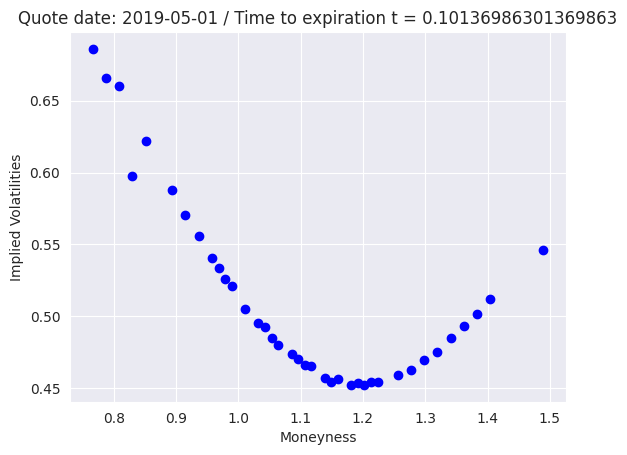

In [39]:
#Code Cell 8

qd1 = quote_dates[52]

call_data_fixed_qd = call_data_new[call_data_new[' [QUOTE_DATE]']==qd1].copy()

T = call_data_fixed_qd['tte'].values

D = call_data_fixed_qd[call_data_fixed_qd['tte'] == T[10]].copy()

A1 = D['Moneyness'].values
B1 = D['Imp_Vol'].values

plt.plot(A1, B1, 'bo')
plt.title(f'Quote date: {qd1} / Time to expiration t = {T[10]}')
plt.xlabel('Moneyness')
plt.ylabel('Implied Volatilities')
plt.show()


The **S-1D kernel smoothing method** fits the data in such a scatter plot with the curve $\sigma = f_h(m, t_{*})$, where
$$f_h(m, t_{*}) = \sum_{i =1}^p \frac{k(m - m_i,h)\sigma_i}{\sum_{1=1}^pk(m - m_i,h) },$$

and:

*   $(m_1,\sigma_1), \ldots, (m_p,\sigma_p)$ are the observations corresponding to the time to expiration $t_{*}$.
*  $k(x, h)$ is once again the kernel function
$$k(x,h) = \frac{1}{\sqrt{2\pi}} e^{\frac{x^2}{2h}}.$$

The value $\hat{\sigma}(m,t_{*}) := f_h(m, t_{*})$ is then the implied volatility estimate corresponding to the tuple $(m,t_{*})$.

Note that we are only performing the kernel regression in the *'moneyness'* direction while keeping the time to expiration fixed. This is the reason why we refer to our method as *'1-dimensional.'*


In [40]:
#Code Cell 9

#The function below is the same as the function kernel_est, but now we change our notation
#to emphasize that we are working with moneyness and implied volatilities.

def kernel_sigmas(input_mon_values, obs_mon_values, obs_imp_vols, bandwidth):

  '''
    S-1D kernel smoothing method.
    Inputs:
    input_mon_values = moneyness values we will plug into f_h(x)
    obs_mon_values = observed moneyness values
    obs_imp_vols = observed implied volatilities
    bandwidth = bandwidth paramater h

  '''

  def kernel(x, bandwidth):
    h = bandwidth
    pi = np.pi
    return (1/np.sqrt(2*pi))*np.exp((-x**2)/(2*h))

  bw = bandwidth
  M = np.array(input_mon_values)
  sigmas = obs_imp_vols

  est_sigmas = np.zeros(len(M))

  for j in range(len(M)):
    est_sigmas[j] = np.sum((kernel(M[j] - obs_mon_values, bw)*sigmas)/(np.sum(kernel(M[j] - obs_mon_values, bw))))

  return est_sigmas

This method is essentially the same as the kernel smoothing method given in [5], but with two essential differences:

1.   We do not implement the 'linear extrapolation' step described in [5] to enlarge the set of 'observed points' $(m_i,\sigma_i)$ (see pages 331 and 332 of [5]).
2.   We do not use the rule-of-thumb used in [5] to determine the bandwidth parameter $h$ (see page 331 of [5]).

In the S-1D kernel smoothing method, we replace 1. and 2. above with an alternate process for determining the appropriate value for the bandwidth parameter, which we shall describe in the next section.


## 2. Determining the Bandwidth Parameter

As we saw in Section 1, incorrect choices for the bandwidth parameter $h$ can lead to overfitting or underfitting.

To determine the correct value of $h$ we should use to produce implied volatility estimates via the S-1D kernel smoothing method for a specific quote date, we will perform a leave-one-out cross-validation (LOOCV) using the data corresponding to that quote date.

The LOOCV works as follows:

1.   Fix a value $h$.
2.   For each observation of the form $(m_j, \sigma_j, t_j)$, let $\hat{\sigma}_j^{h}$ be the estimate produced by implementing the S-1D kernel smoothing method *without* the observation $(m_j, \sigma_j, t_j)$ (i.e., we *leave out* $(m_j, \sigma_j, t_j)$ in the kernel regression).
3. Then, we compute the *root mean squared error*
$$ \mathrm{RSME}_h = \sqrt{\frac{1}{N}\sum_{j=1}^N(\sigma_j - \hat{\sigma}_j^{h})^2}, $$
where $N$ is the total number of observations.

We implement this process for a range of values $h$. Namely, we partition the interval $[0.00025,0.005]$ into subintervals of length $0.00025$, and apply the process described above to the end points of the subintervals in this partition. The value $h$ that gives the lowest $\mathrm{RSME}_h$ will be our choice of bandwidth parameter.



In [41]:
#Code Cell 10

# Fix a specific quote date (later, we will compare the S-1D kernel smoothing
# method and the Heston model on this quote date).

qd = quote_dates[73]  # You can find the index of a specific quote date in Code Cell 7.

r = .04  # Set the risk-free interest rate at r = 0.04.

print(f'We will perform our LOOCV using the data from the quote date {qd}.')

print('-----'*20)

# Next, we extract the portion of our data corresponding to the quote date we fixed.

X = call_data_new[call_data_new[' [QUOTE_DATE]']==qd].copy()
strikes = X[' [STRIKE]'].values
market_prices = X['mid'].values
ttes = X['tte'].values
market_ivs = X['Imp_Vol'].values
S0 = X[' [UNDERLYING_LAST]'].iloc[0]

print(X)

We will perform our LOOCV using the data from the quote date 2019-05-31.
----------------------------------------------------------------------------------------------------
       [QUOTE_DATE]   [UNDERLYING_LAST]  [EXPIRE_DATE]   [DTE]   [STRIKE]  \
28522    2019-05-31              185.16     2019-07-05    35.0      140.0   
28523    2019-05-31              185.16     2019-07-05    35.0      145.0   
28524    2019-05-31              185.16     2019-07-05    35.0      150.0   
28525    2019-05-31              185.16     2019-07-05    35.0      155.0   
28526    2019-05-31              185.16     2019-07-05    35.0      160.0   
...             ...                 ...            ...     ...        ...   
29310    2019-05-31              185.16     2020-03-20   294.0      250.0   
29311    2019-05-31              185.16     2020-03-20   294.0      255.0   
29312    2019-05-31              185.16     2020-03-20   294.0      260.0   
29313    2019-05-31              185.16     2020-03-20  

In [42]:
#Code Cell 11

# The following function computes the RMSE for our LOOCV for a single value H.

def RMSE_fixed_H(D,H):

  def single_sq_error(D,j,H):

    E = D.drop(D.index[j])

    t = D.iloc[j,0]
    x = D.iloc[j,1]
    y = D.iloc[j,2]

    def kernel(x, bandwidth):
      h = bandwidth
      pi = np.pi
      return (1/np.sqrt(2*pi))*np.exp((-x**2)/(2*h))

    F = E[E.iloc[:, 0] == t].copy()

    obs_mon = F.iloc[:, 1].values
    sigmas = F.iloc[:, 2].values

    est_sigma = np.sum((kernel(x - obs_mon, H)*sigmas)/(np.sum(kernel(x - obs_mon, H))))

    return (y - est_sigma)**2

  D_copies = [D.copy() for j in range(len(D))]
  J = np.arange(len(D))

  squared_errors = np.array([single_sq_error(D_copies[j],J[j],H) for j in range(len(J))])

  RMSE = np.sqrt(np.mean(squared_errors))

  return RMSE



The bandwidth parameter that minimizes the RMSE is: 0.00175

----------------------------------------------------------------------------------------------------


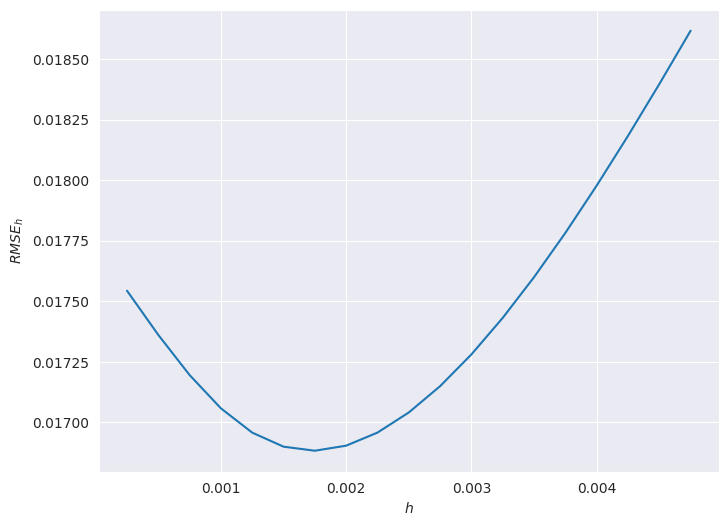

In [43]:
#Code Cell 12

# Now, we extract the relevant columns from the data frame X.

Y = X[['tte','Moneyness','Imp_Vol']].copy()

# Finally, the following code performs the LOOCV and outputs
# the bandwidth parameter that minimizes the RMSE.

bandwidths = np.arange(0.00025, 0.005, 0.00025)

Total_bws = len(bandwidths)

Y_copies = [Y.copy() for j in range(Total_bws)]

list_RMSEs = np.array([RMSE_fixed_H(Y_copies[j],bandwidths[j]) for j in range(Total_bws)])

optimal_bw = bandwidths[np.argmin(list_RMSEs)]

print(f'The bandwidth parameter that minimizes the RMSE is: {optimal_bw}')

print()
print('-----'*20)
plt.figure(figsize = (8,6))
plt.plot(bandwidths,list_RMSEs)
plt.xlabel(r'$h$')
plt.ylabel(r'$RMSE_h$')
plt.show()

In this graph, we are plotting all points of the form $(h,\mathrm{RMSE}_h)$ for $h \in [0.00025, 0.005]$. We interpret this graph as follows:

*   High values of $h$ give high values for $\mathrm{RMSE}_h$, which is evidence of underfitting.
*   On the other hand, very low values of $h$ also yield high values for $\mathrm{RMSE}_h$, which is evidence of overfitting.



## 3. Comparing the S-1D Kernel Smoothing Method and the Heston Model

### 3.1. The Heston Model

In this section, we follow the discussion given in [1].

According to the Heston model, the behavior of a risky asset $S_t$ (e.g., a stock) and its volatility $v_t$ follow a pair of stochastic differential equations of the form

$$dS_t = \mu S_t\,dt + \sqrt{v_t}\,S_t\,dB_t^{(1)}, \qquad
dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dB_t^{(2)}, \qquad
dB_t^{(1)}dB_t^{(2)} = \rho\,dt.$$

The key parameters that describe the Heston model are $v_0, \kappa, \theta, \xi, \rho$, where:

- $v_0$ is the initial variance;
- $\kappa$ is the **mean-reversion rate** of the variance process;
- $\theta$ is the **long-run variance level** of the variance process;
- $\xi$ is the **volatility of volatility**;
- $\rho$ is the correlation of the two Brownian motions $B_t^{(1)}$ and $B_t^{(2)}$.

Under the Heston model, it is possible to write down a closed-form formula for the price $C(K, t; v_0, \kappa, \theta, \xi, \rho)$ of a European style option with strike $K$ and time to expiration $t$. The interested reader can find this formula in [2].

The following code from [4] computes the price (under the Heston model) of multiple European style option contracts with the same underlying $S_t$ simultaneously.  


In [44]:
#Code Cell 13

# Heston model pricing function

def heston_call_vectorized(
    S0, strikes, ttes, v0, r, kappa, theta, xi, rho,
    integration_limit=100,
    n_phi=1000
):
    """
    strikes and ttes must have the same shape.
    Returns an array of Heston call prices with the same shape.
    """


    original_shape = strikes.shape

    K = strikes.ravel()
    tau = ttes.ravel()

    i = 1j
    a = kappa * theta

    # Avoid phi = 0 because the integrand contains division by phi.
    phi = np.linspace(1e-8, integration_limit, n_phi)


    phi = phi[:, None]
    K = K[None, :]
    tau = tau[None, :]

    x = np.log(S0 / K)

    def integrand(Pnum):
        if Pnum == 1:
            u = 0.5
            b = kappa - rho * xi
        else:
            u = -0.5
            b = kappa

        d = np.sqrt(
            (rho * xi * i * phi - b)**2
            - xi**2 * (2 * u * i * phi - phi**2)
        )

        # Little Heston trap formulation
        g = (b - rho * xi * i * phi - d) / (
            b - rho * xi * i * phi + d
        )

        C = (
            r * i * phi * tau
            + (a / xi**2)
            * (
                (b - rho * xi * i * phi - d) * tau
                - 2 * np.log((1 - g * np.exp(-d * tau)) / (1 - g))
            )
        )

        D = (
            (b - rho * xi * i * phi - d) / xi**2
            * ((1 - np.exp(-d * tau)) / (1 - g * np.exp(-d * tau)))
        )

        f = np.exp(i * phi * x + C + D * v0)

        return np.real(f / (i * phi))

    int_P1 = trapezoid(integrand(1), phi[:, 0], axis=0)
    int_P2 = trapezoid(integrand(2), phi[:, 0], axis=0)

    P1 = 0.5 + int_P1 / np.pi
    P2 = 0.5 + int_P2 / np.pi

    prices = S0 * P1 - K.ravel() * np.exp(-r * tau.ravel()) * P2

    return prices.reshape(original_shape)

### 3.2. Calibration of the Heston Model

The discussion in this section also follows [1]. Let $\boldsymbol\theta = [v_0, \kappa, \theta, \xi, \rho]$.

Before we can compare the S-1D kernel smoothing method and the Heston model, we will *calibrate* the Heston model using the observations from the quote date we have already fixed (see code cell 10). That is, we wish to find the $\boldsymbol\theta$ that minimizes $\rVert r(\boldsymbol\theta)\rVert^2$, where $r_i(\boldsymbol\theta) = C(K_i,\tau_i; \boldsymbol\theta) - C^*(K_i,\tau_i)$ are the price errors.


In [45]:
#Code Cell 14

print(f'Our fixed quote date is {qd}.') #Quote date fixed in Code cell 10.
print()
print(f'Next, we calibrate the Heston model using the data from this quote date.')

Our fixed quote date is 2019-05-31.

Next, we calibrate the Heston model using the data from this quote date.


In [47]:
#Code Cell 15

# Function for computing price errors

def error_price(parameters,S0,strikes,ttes,r,market_prices):
    v0,kappa,theta,xi,rho = parameters
    model_prices = heston_call_vectorized(S0,strikes,ttes,v0,r,kappa,theta,xi,rho)

    return model_prices - market_prices



# Calibration of the Heston Model

X = call_data_new[call_data_new[' [QUOTE_DATE]']==qd].copy()
strikes = X[' [STRIKE]'].values
market_prices = X['mid'].values
ttes = X['tte'].values
market_ivs = X['Imp_Vol'].values
S0 = X[' [UNDERLYING_LAST]'].iloc[0]

market_vegas = bs_vega(S0,strikes,market_ivs,ttes,r)

v0_initial = .4**2
kappa_initial = 3
theta_initial = .4**2
xi_initial = .5
rho_initial = -.5

parameters = [v0_initial, kappa_initial,theta_initial,xi_initial,rho_initial]

bounds = [[.1**2,.2,.1**2,.5,-.99],[.9**2,15,.9**2, 5,-.01]]

result_price = least_squares(error_price, x0 = parameters,bounds = bounds,\
                             args = (S0,strikes,ttes,r,market_prices), verbose = 0)

print('Calibrated Parameters for minimizing price errors:')
print(result_price.x)

Calibrated Parameters for minimizing price errors:
[ 0.45234275  1.78973739  0.40625248  1.81084585 -0.56070091]


### 3.3. Comparing the S-1D Kernel Smoothing Method and the Heston Model

We will now perform a systematic comparison between the S-1D kernel smoothing method and the Heston model on the quote date we have already fixed (see Code Cell 10).

We will do this in two steps:

1.   *Graphical comparison:* For each time to expiration $t_{*}$ available for the quote date we have fixed, we will plot the observations $(m_i, \sigma_i)$ corresponding to $t_{*}$ (i.e., we plot the volatility curve for $t_{*}$) and fit these observations with the implied volatility estimate functions $g(m,t_{*})$ and $f_h(m,t_{*})$ produced by the Heston model and the S-1D kernel smoothing method respectively. Here, $h$ is the optimal value for the bandwidth parameter we determined in the previous section.
2. *Error comparison:* Then, for the quote date we fixed beforehand, we compute the RMSE for both the Heston model and the S-1D kernel smoothing method
$$ \mathrm{RSME}_{\mathrm{Heston}} = \sqrt{\frac{1}{N}\sum_{j=1}^N(g(m_j,t_j) - \sigma_j)^2} \qquad
\mathrm{RSME}_{\mathrm{Kernel}} = \sqrt{\frac{1}{N}\sum_{j=1}^N(f_h(m_j,t_j) - \sigma_j)^2}, $$
where $N$ is the total number of observations available at our fixed quote date, and $m_j$, $t_j$, $\sigma_j$ are respectively the moneyness, time to expiration, and BS implied volatility corresponding to the $j$th observation.  The model that yields the lower RMSE will be the one that gives the best approximation to the volatility curve.

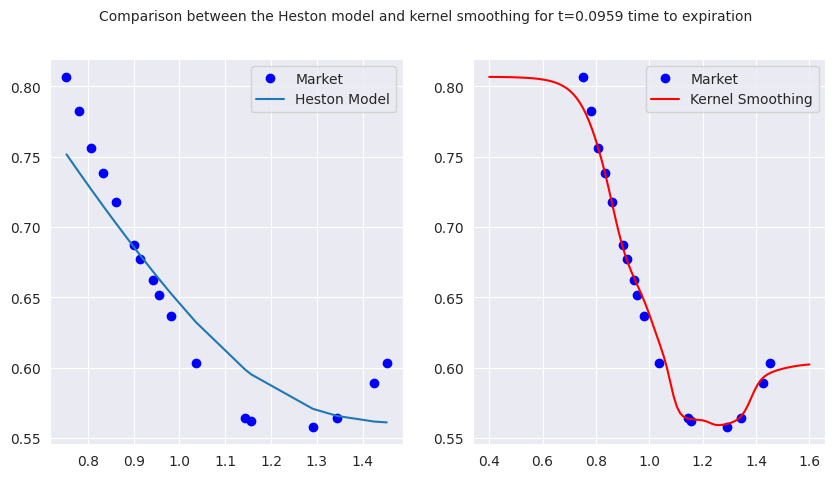

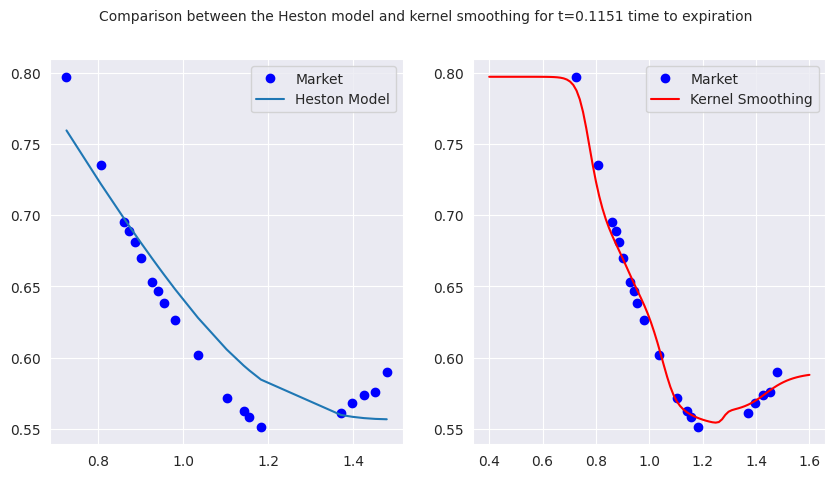

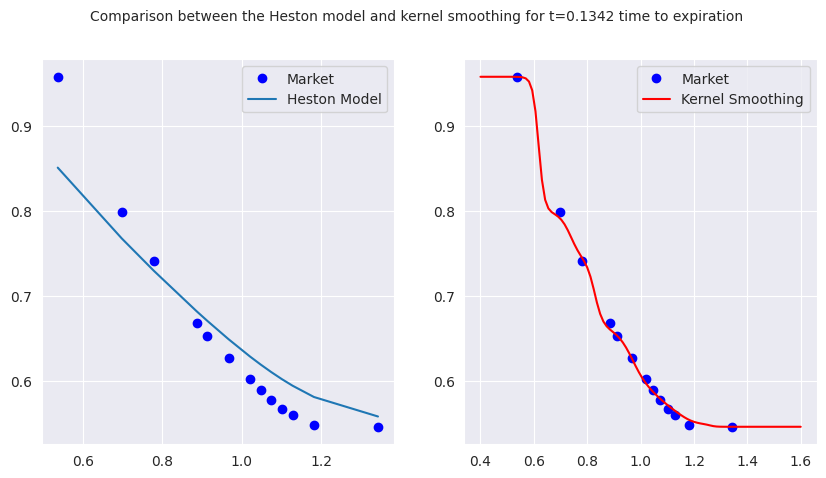

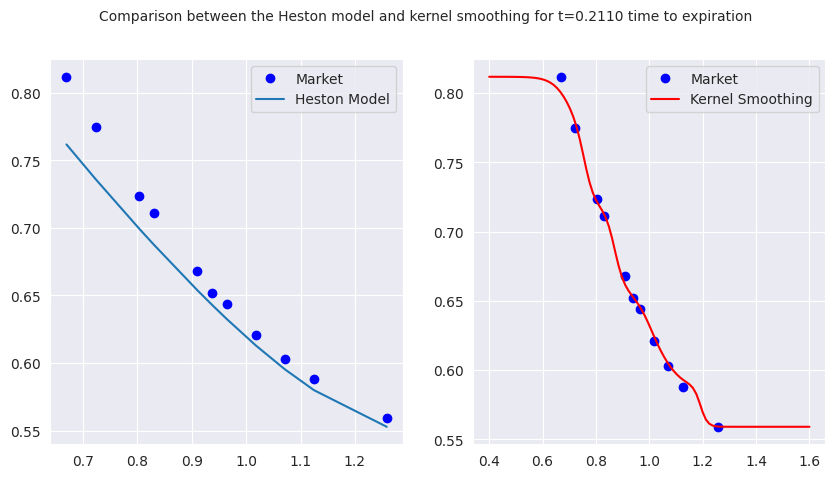

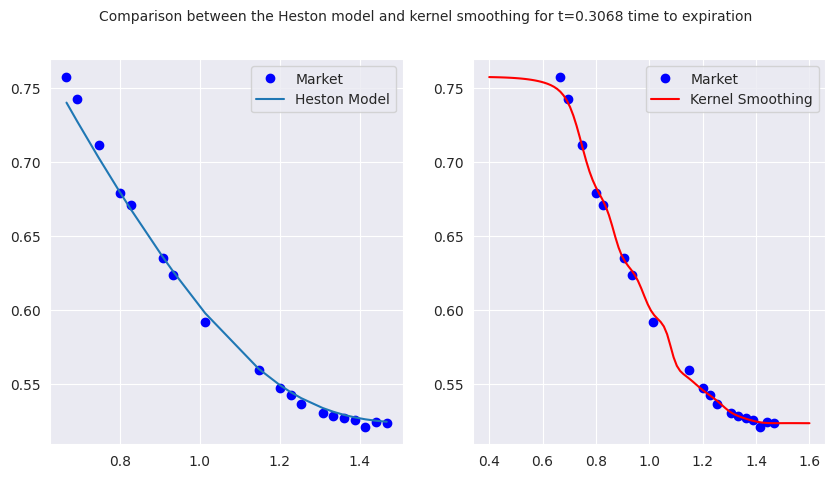

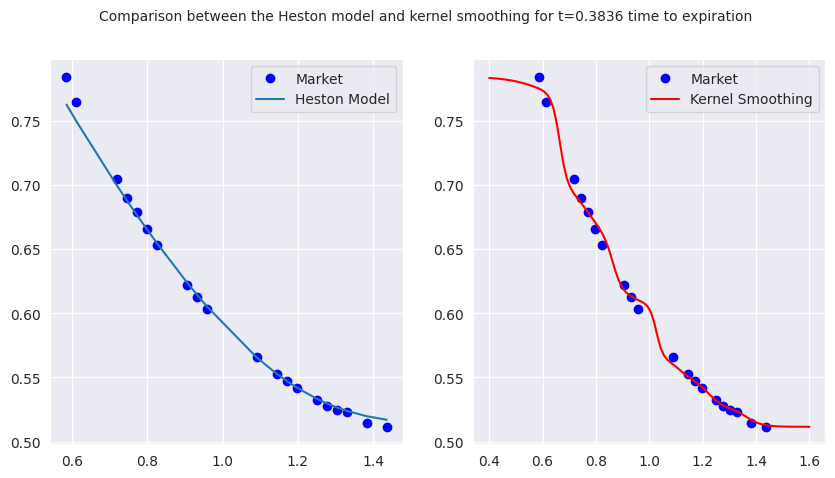

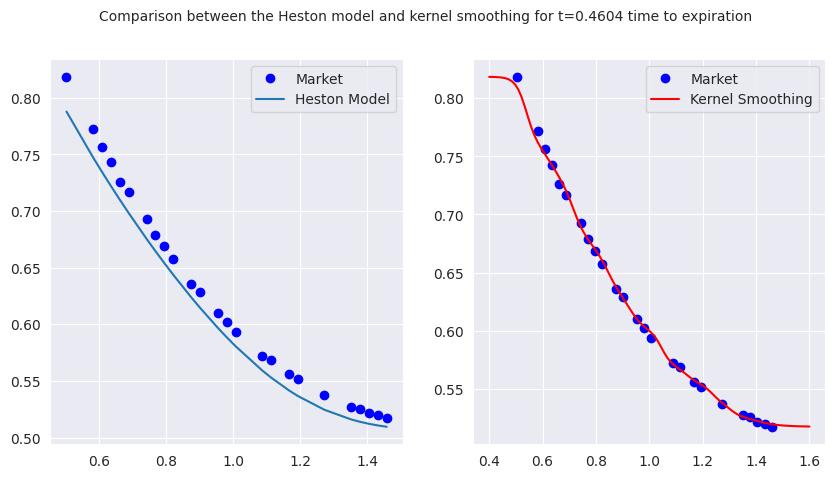

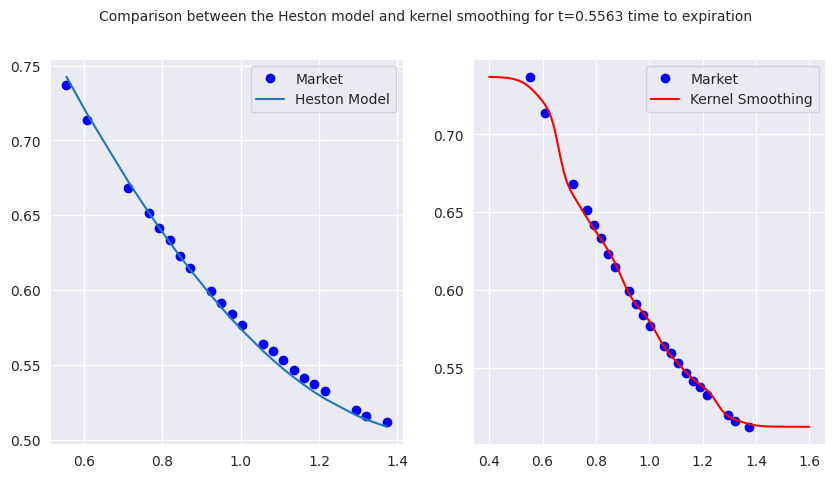

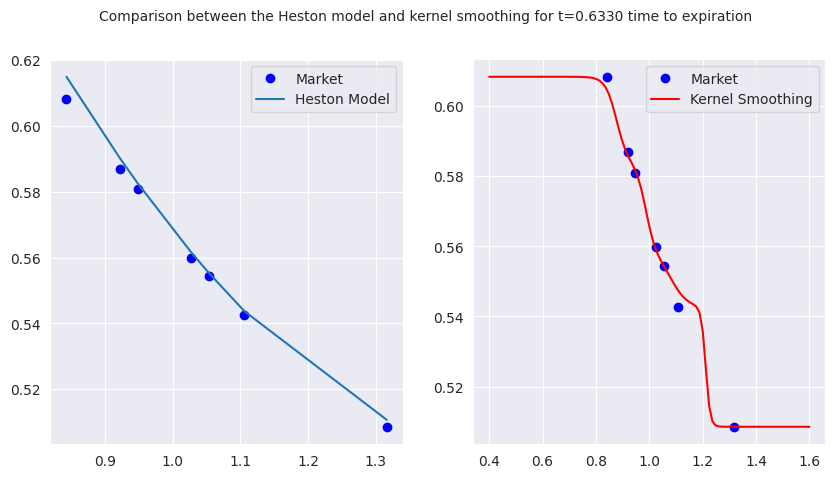

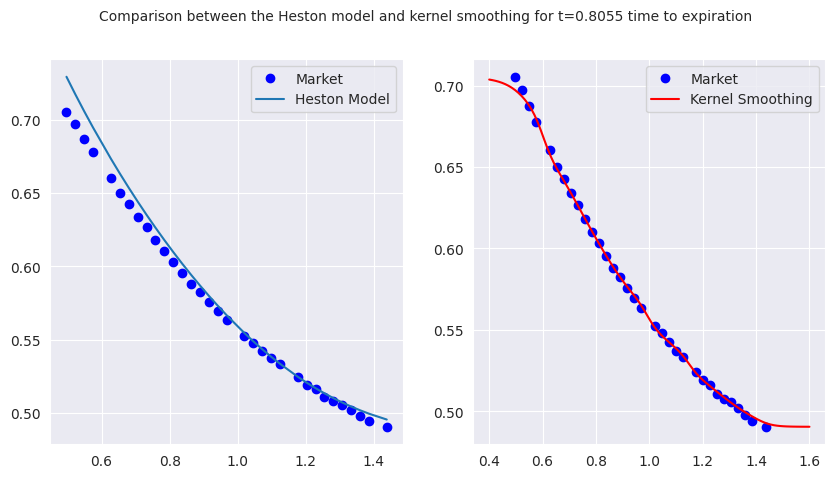

In [48]:
#Code Cell 16

# Graphical comparison of the Heston and Kernel Smooting method

v0_H, kappa_H,theta_H,xi_H,rho_H = result_price.x

input_mon = np.linspace(0.4,1.6,100) # values we will plug into the kernel smoothing function

for t in np.unique(X['tte'].values):

    Y = X[X['tte'] == t].copy()

    market_prices = Y['mid'].values
    strikes = Y[' [STRIKE]'].values
    market_ivs = Y['Imp_Vol'].values
    mon_vals = Y['Moneyness'].values

    Heston_prices = heston_call_vectorized(S0,strikes,t*np.ones(len(strikes)),v0_H,r,kappa_H,theta_H,xi_H,rho_H)
    Heston_ivs = bs_call_iv_vectorized(S0*np.ones(len(strikes)),strikes,t*np.ones(len(strikes)),r,Heston_prices)

    kernel_ivs = kernel_sigmas(input_mon, mon_vals, market_ivs, optimal_bw)

    fig,ax = plt.subplots(1,2,figsize = (10,5))

    ax[0].plot(mon_vals,market_ivs, 'bo', label = 'Market')
    ax[0].plot(mon_vals, Heston_ivs, label = 'Heston Model')
    ax[0].legend()

    ax[1].plot(mon_vals, market_ivs, 'bo', label = 'Market')
    ax[1].plot(input_mon, kernel_ivs, color = 'r', label = 'Kernel Smoothing')
    ax[1].legend()

    plt.suptitle(f'Comparison between the Heston model and kernel smoothing for t={t:.4f} time to expiration', size = 10)
    plt.show()

Finally, we compute the RMSEs for the Heston model and the S-1D kernel smoothing method on the quote date we fixed.

In [49]:
#Code Cell 17

# Error comparison for the Heston model and S-1D kernel smoothing method

# The following code computes the root mean squared errors (RMSEs) for the
# Heston model and the S-1D kernel smoothing method.

sq_errors_heston = np.array([])

sq_errors_kernel = np.array([])

for t in np.unique(X['tte'].values):

    Y = X[X['tte'] == t].copy()

    market_prices = Y['mid'].values
    strikes = Y[' [STRIKE]'].values
    market_ivs = Y['Imp_Vol'].values
    mon_vals = Y['Moneyness'].values

    Heston_prices = heston_call_vectorized(S0,strikes,t*np.ones(len(strikes)),v0_H,r,kappa_H,theta_H,xi_H,rho_H)
    Heston_ivs = bs_call_iv_vectorized(S0*np.ones(len(strikes)),strikes,t*np.ones(len(strikes)),r,Heston_prices)

    kernel_ivs = kernel_sigmas(mon_vals, mon_vals, market_ivs, optimal_bw)

    new_sq_errors_heston = (Heston_ivs - market_ivs)**2
    sq_errors_heston = np.append(sq_errors_heston, new_sq_errors_heston)

    new_sq_errors_kernel = (kernel_ivs - market_ivs)**2
    sq_errors_kernel = np.append(sq_errors_kernel, new_sq_errors_kernel)



RMSE_Heston = np.sqrt(np.mean(sq_errors_heston))
RMSE_kernel = np.sqrt(np.mean(sq_errors_kernel))


print(f'The RMSE of the Heston model on {qd} is: {RMSE_Heston}')
print()
print(f'The RMSE of the Kernel Smoothing model on {qd} is: {RMSE_kernel}')



The RMSE of the Heston model on 2019-05-31 is: 0.01783226131383604

The RMSE of the Kernel Smoothing model on 2019-05-31 is: 0.004646201535937928


## 4. Conclusions

1.   Based on the analysis carried out in this project, we conclude that, as a tool for estimating implied volatilities, the S-1D kernel smoothing method outperforms the Heston model. In Table 1 of this project's executive summary, we record the RMSEs for the Heston Model and the S-1D kernel smoothing method for ten different quote dates. For each of these dates, the S-1D kernel smoothing method produced a lower RMSE than the Heston model. Running this project's code for any other quote date in our dataset seems to yield the same outcome.
2. An advantage of the S-1D kernel smoothing method is that it is easy to interpret. More precisely, for an unobserved tuple $(m,t_{*})$ that was not used to perform the kernel regression, we interpret the estimate $f_h(m,t_{*})$ as the *local average* of implied volatilities $\sigma_i$ corresponding to tuples $(m_i,t_{*})$ with $m_i$ sufficiently close to $m$.
3. A limitation of the S-1D kernel smoothing method is that it might be computationally expensive to determine the optimal bandwidth parameter $h$ via a LOOCV. In 'Code Cell 12,' we limited our search for the optimal $h$ to the interval $[0.00025,0.005]$. This choice was made on an empirical basis. After testing the S-1D kernel smoothing method for multiple values of $h$ and multiple quote dates, it seemed that the optimal $h$ was always within this range of values. However, increasing the length of the interval (say, to $[0.0001, 0.04]$) significantly increases the computational cost involved in the LOOCV.
4. Finally, another limitation of the S-1D kernel smoothing method is its sensitivity to outliers. For example, the figure below to the left shows the volatility curve model produced via the S-1D kernel smoothing method using the data $(m_i,\sigma_i)$ corresponding to the quote date 2019-05-31 and time to expiration $t = 0.6330$. On the other hand, the figure to the right shows a new volatility curve model produced via the S-1D kernel smoothing method after replacing one of the observed implied volatilities $\sigma_i$ with a significantly low value. The presence of this outlier completely distorts the output of the S-1D kernel smoothing method. A solution to this issue (which we will address in a future project) is to filter out any outliers before performing the kernel regression, or design a kernel smoothing method that assigns less weight to such outliers.




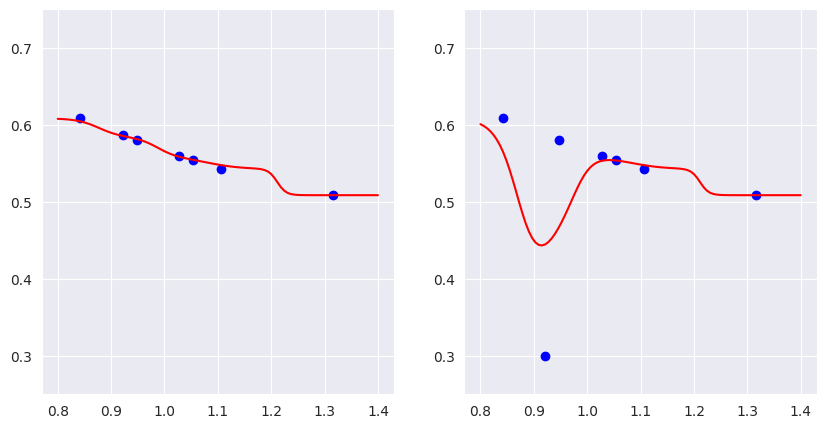

In [50]:
#Code Cell 18

T = np.unique(X['tte'].values)

Z = X[X['tte'] == T[-2]].copy()

market_ivs = Z['Imp_Vol'].values
mon_vals = Z['Moneyness'].values
input_mon = np.linspace(0.8,1.4,100)

new_market_ivs = market_ivs.copy()
new_market_ivs[1] = 0.3

kernel_ivs_1 = kernel_sigmas(input_mon, mon_vals, market_ivs, optimal_bw)

kernel_ivs_2 = kernel_sigmas(input_mon, mon_vals, new_market_ivs, optimal_bw)

fig,ax = plt.subplots(1,2,figsize = (10,5))

ax[0].plot(mon_vals,market_ivs, 'bo')
ax[0].plot(input_mon, kernel_ivs_1, color = 'r')
ax[0].set_ylim(top=0.75)
ax[0].set_ylim(bottom=0.25)


ax[1].plot(mon_vals, new_market_ivs, 'bo')
ax[1].plot(input_mon, kernel_ivs_2, color = 'r')
ax[1].set_ylim(top=0.75)
ax[1].set_ylim(bottom=0.25)


plt.show()


**Note:** To conclude this project, we remark that our root-solving function produces implied volatility values close to zero for some quote dates. These low values affect the volatility curve approximations produced by the Heston model and the S-1D kernel smoothing method. However, even for a quote date where this happens (such as 2019-06-28, one of the quote dates included in Table 1 of the executive summary), the S-1D kernel smoothing method still produced a lower RMSE than the Heston model.  

## References

[1] A. Farsad, *A fast calibration of the Heston model*, Erdös Institute - Quantitative Finance Program, Summer 2026. Final project.

[2] J. Gatheral, *The volatility surface: A practitioner's guide*, Wiley Finance (2006).

[3] T. Hastie, R. Tibshirani, J. Friedman, *The elements of statistical learning: Data mining, inference, and prediction*, Springer Series in Statistics, 2nd edition (2017).

[4] T. Polstra, *Model calibration and a summary of the Heston model*, Erdös Institute - Quantitative Finance Program, Summer 2026. Jupyter notebook.

[5] M. Ulrich, S. Walther, *Option-implied information: What's the vol surface got to do with it?*, Review of Derivatives Research (2020) 23:323–355.